Installing YOLO\
Ultralytics' Python API supports loading a pretrained model and training it against a custom dataset using a dataset YAML file.

In [3]:
!pip install -q ultralytics roboflow

import ultralytics

print("Ultralytics version:", ultralytics.__version__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 29.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 89.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 9.3 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.175


Checking the GPU

In [4]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not detected")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


Download the Roboflow Dataset\
YOLO datasets use a YAML configuration defining the training, validation and test data and class names.


In [5]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="siB1OGhXN0kGj0mPwzwM")
project = rf.workspace("ece4078h3").project("pork-rasher-error-packaging-rj5da")
version = project.version(1)
dataset = version.download("yolov8")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Pork-Rasher-Error(Packaging)-1 in yolov8:: 100%|██████████| 3915/3915 [00:00<00:00, 7505.56it/s]


Finding the data.yaml

In [6]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file == "data.yaml":
            print(os.path.join(root, file))

DATA_YAML = "/content/Pork-Rasher-Error(Packaging)-1/data.yaml"

print(DATA_YAML)

/content/Pork-Rasher-Error(Packaging)-1/data.yaml
/content/Pork-Rasher-Error(Packaging)-1/data.yaml


Inspect the dataset YAML

In [7]:
with open(DATA_YAML, "r") as f:
    print(f.read())

names:
- loose-meat
- packaging-error
- twisted-meat
- unsealed
- wrinkle
nc: 5
roboflow:
  license: CC BY 4.0
  project: pork-rasher-error-packaging-rj5da
  url: https://universe.roboflow.com/ece4078h3/pork-rasher-error-packaging-rj5da/dataset/1
  version: 1
  workspace: ece4078h3
test: ../test/images
train: ../train/images
val: ../valid/images



Check the dataset before training

In [8]:
import os
from pathlib import Path

data_root = Path(DATA_YAML).parent

print("Dataset directory:")
print(data_root)

for path in data_root.iterdir():
    print(path)


from pathlib import Path

image_extensions = ["*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG"]

for split in ["train", "valid", "val", "test"]:
    split_path = data_root / split

    if split_path.exists():
        count = sum(
            len(list((split_path / "images").glob(ext)))
            for ext in image_extensions
            if (split_path / "images").exists()
        )
        print(f"{split}: {count} images")

Dataset directory:
/content/Pork-Rasher-Error(Packaging)-1
/content/Pork-Rasher-Error(Packaging)-1/README.dataset.txt
/content/Pork-Rasher-Error(Packaging)-1/README.roboflow.txt
/content/Pork-Rasher-Error(Packaging)-1/data.yaml
/content/Pork-Rasher-Error(Packaging)-1/test
/content/Pork-Rasher-Error(Packaging)-1/train
/content/Pork-Rasher-Error(Packaging)-1/valid
train: 1764 images
valid: 115 images
test: 76 images


Load YOLOv8 \
I'm fine-tuning a pretrained model, rather than training from scratch. Starting from pretrained weights is the standard approach for custom object detection and generally reduces the amount of training required.

In [9]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

Training my first model \
Which gives me a baseline model

In [10]:
results = model.train(
    data=DATA_YAML,
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    project="/content/mma3001_results",
    name="yolov8n_baseline",
    patience=10,
    plots=True
)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Pork-Rasher-Error(Packaging)-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_baseline, nbs=64, nms=None, ops

Looking at the training results




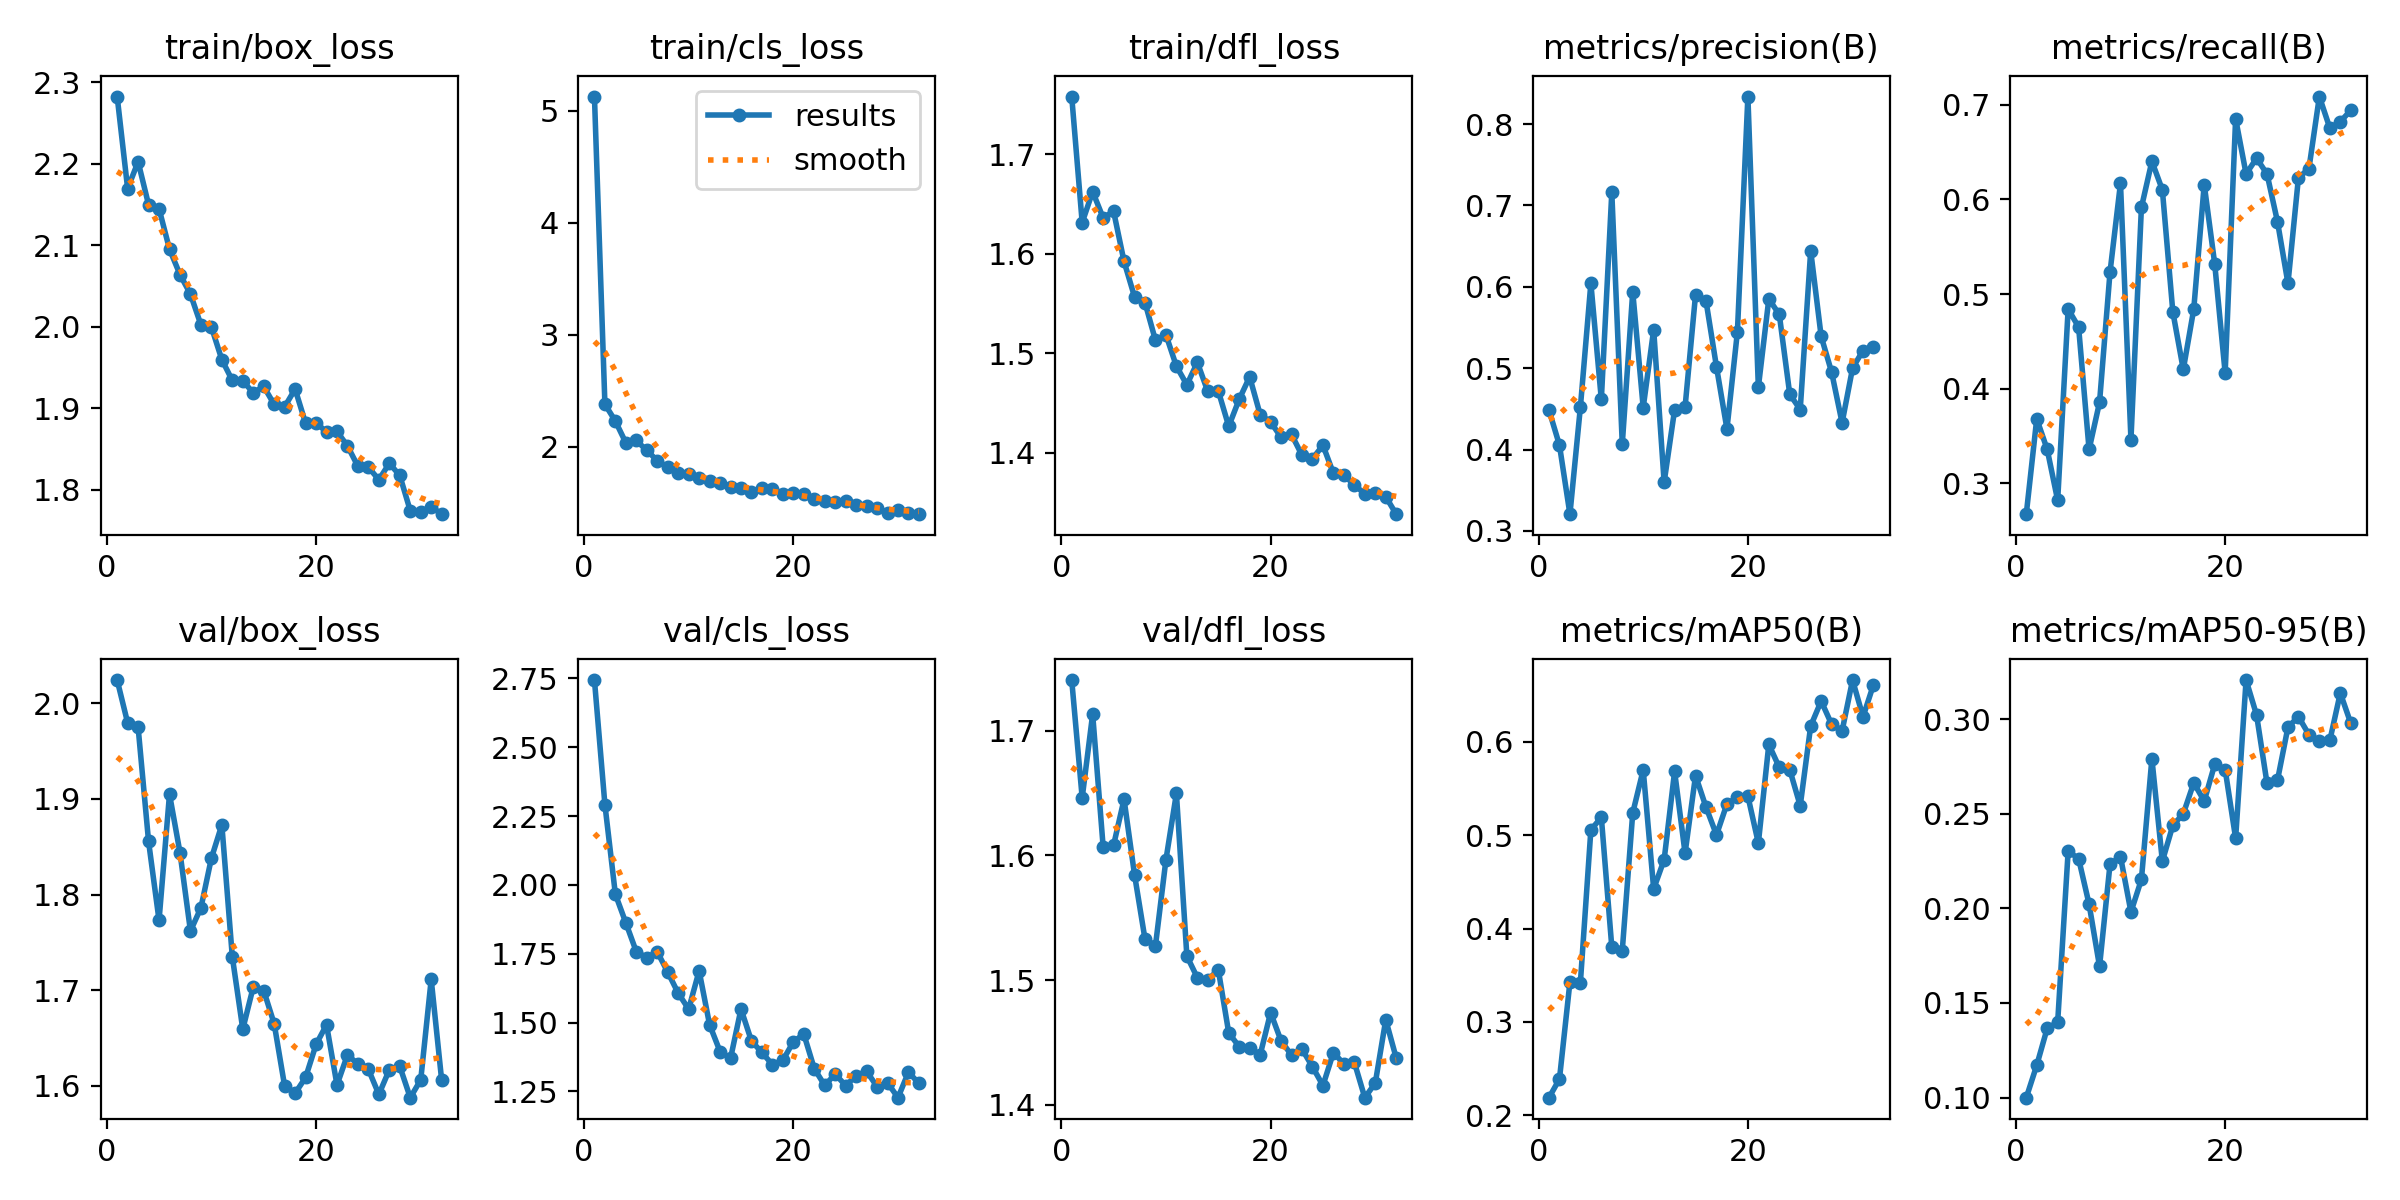

In [11]:
from IPython.display import Image, display

display(
    Image(
        filename="/content/mma3001_results/yolov8n_baseline/results.png"
    )
)

Validate the trained model\
Ultralytics validation provides metrics including mAP50 and mAP50-95, as well as precision/recall-related evaluation information.

In [12]:
best_model = YOLO(
    "/content/mma3001_results/yolov8n_baseline/weights/best.pt"
)

metrics = best_model.val(
    data=DATA_YAML,
    split="val"
)

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1314.3±288.6 MB/s, size: 51.0 KB)
val: Scanning /content/Pork-Rasher-Error(Packaging)-1/valid/labels.cache... 115 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 115/115 26.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.7it/s 2.9s
                   all        115        143      0.585      0.627      0.598       0.32
            loose-meat          5          5      0.489        0.8      0.643      0.315
       packaging-error         30         45      0.528        0.1      0.224     0.0801
          twisted-meat          4          5      0.469        0.8      0.676      0.372
              unsealed         85         88      0.856      0.807      0.849      0.512
Speed: 3.8ms preprocess, 6.

Run my model on test images

In [13]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
test_results = best_model.predict(
    source=f"{data_root}/test/images",
    conf=0.25,
    save=True,
    save_txt=True,
    save_conf=True
)


image 1/76 /content/Pork-Rasher-Error(Packaging)-1/test/images/frame_with_red_102_jpg.rf.8659eac39d6481b97dd7cd9cd5b53d10.jpg: 640x640 1 unsealed, 12.5ms
image 2/76 /content/Pork-Rasher-Error(Packaging)-1/test/images/frame_with_red_121_jpg.rf.b9703132d3c2ed0d47b4abbff0161da4.jpg: 640x640 1 twisted-meat, 12.5ms
image 3/76 /content/Pork-Rasher-Error(Packaging)-1/test/images/frame_with_red_1271_jpg.rf.22e9aa3a2caa406e08bbe0e9cc1979a7.jpg: 640x640 1 unsealed, 12.5ms
image 4/76 /content/Pork-Rasher-Error(Packaging)-1/test/images/frame_with_red_1298_jpg.rf.dd1b58a843b4aa0fa35a3deb2d94a00b.jpg: 640x640 (no detections), 12.5ms
image 5/76 /content/Pork-Rasher-Error(Packaging)-1/test/images/frame_with_red_1405_jpg.rf.dffa5de43a67cd0101bc0d29a4761afe.jpg: 640x640 1 unsealed, 12.5ms
image 6/76 /content/Pork-Rasher-Error(Packaging)-1/test/images/frame_with_red_1427_jpg.rf.bbc3b5eb81e27d8beaad124f9cd2cbff.jpg: 640x640 1 unsealed, 12.5ms
image 7/76 /content/Pork-Rasher-Error(Packaging)-1/test/images

Number of prediction images: 76


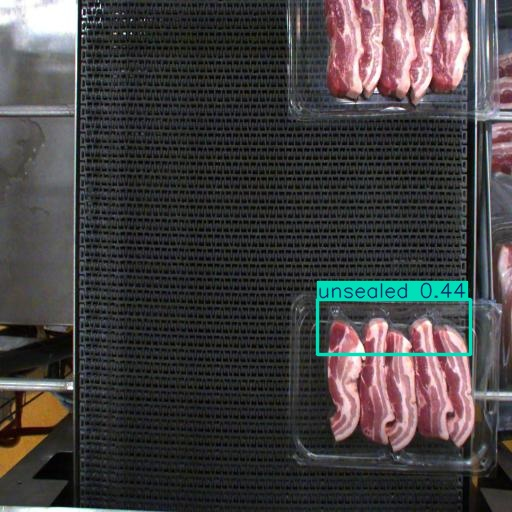

In [15]:
from pathlib import Path
from IPython.display import Image, display

prediction_dir = Path("/content/runs/detect/predict")

images = list(prediction_dir.glob("*.jpg")) + list(prediction_dir.glob("*.png"))

print("Number of prediction images:", len(images))

if images:
    display(Image(filename=str(images[0])))

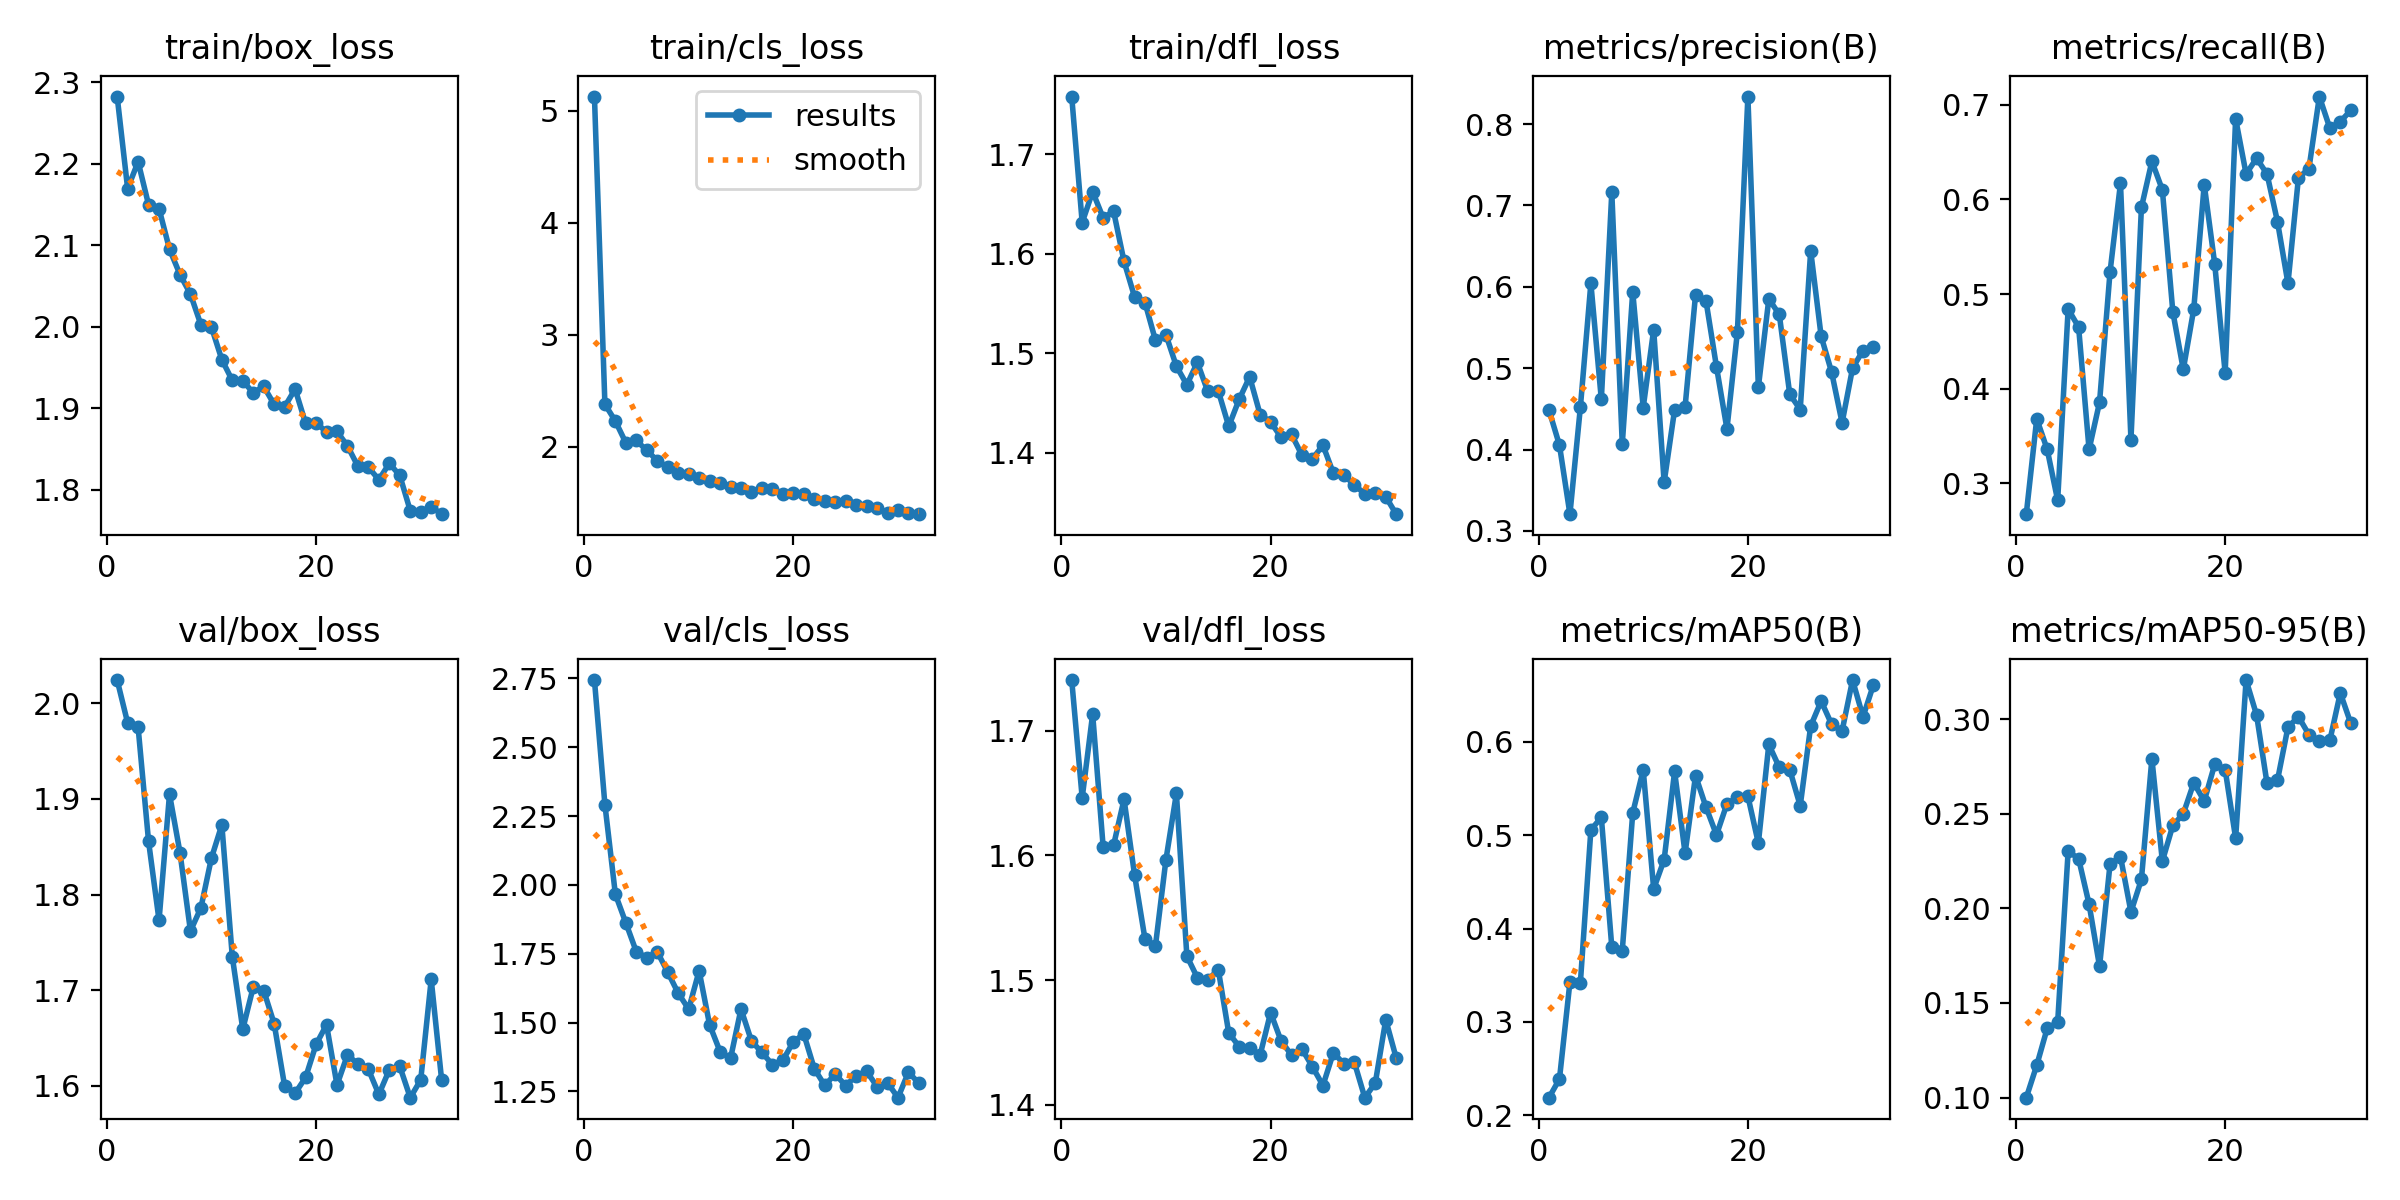

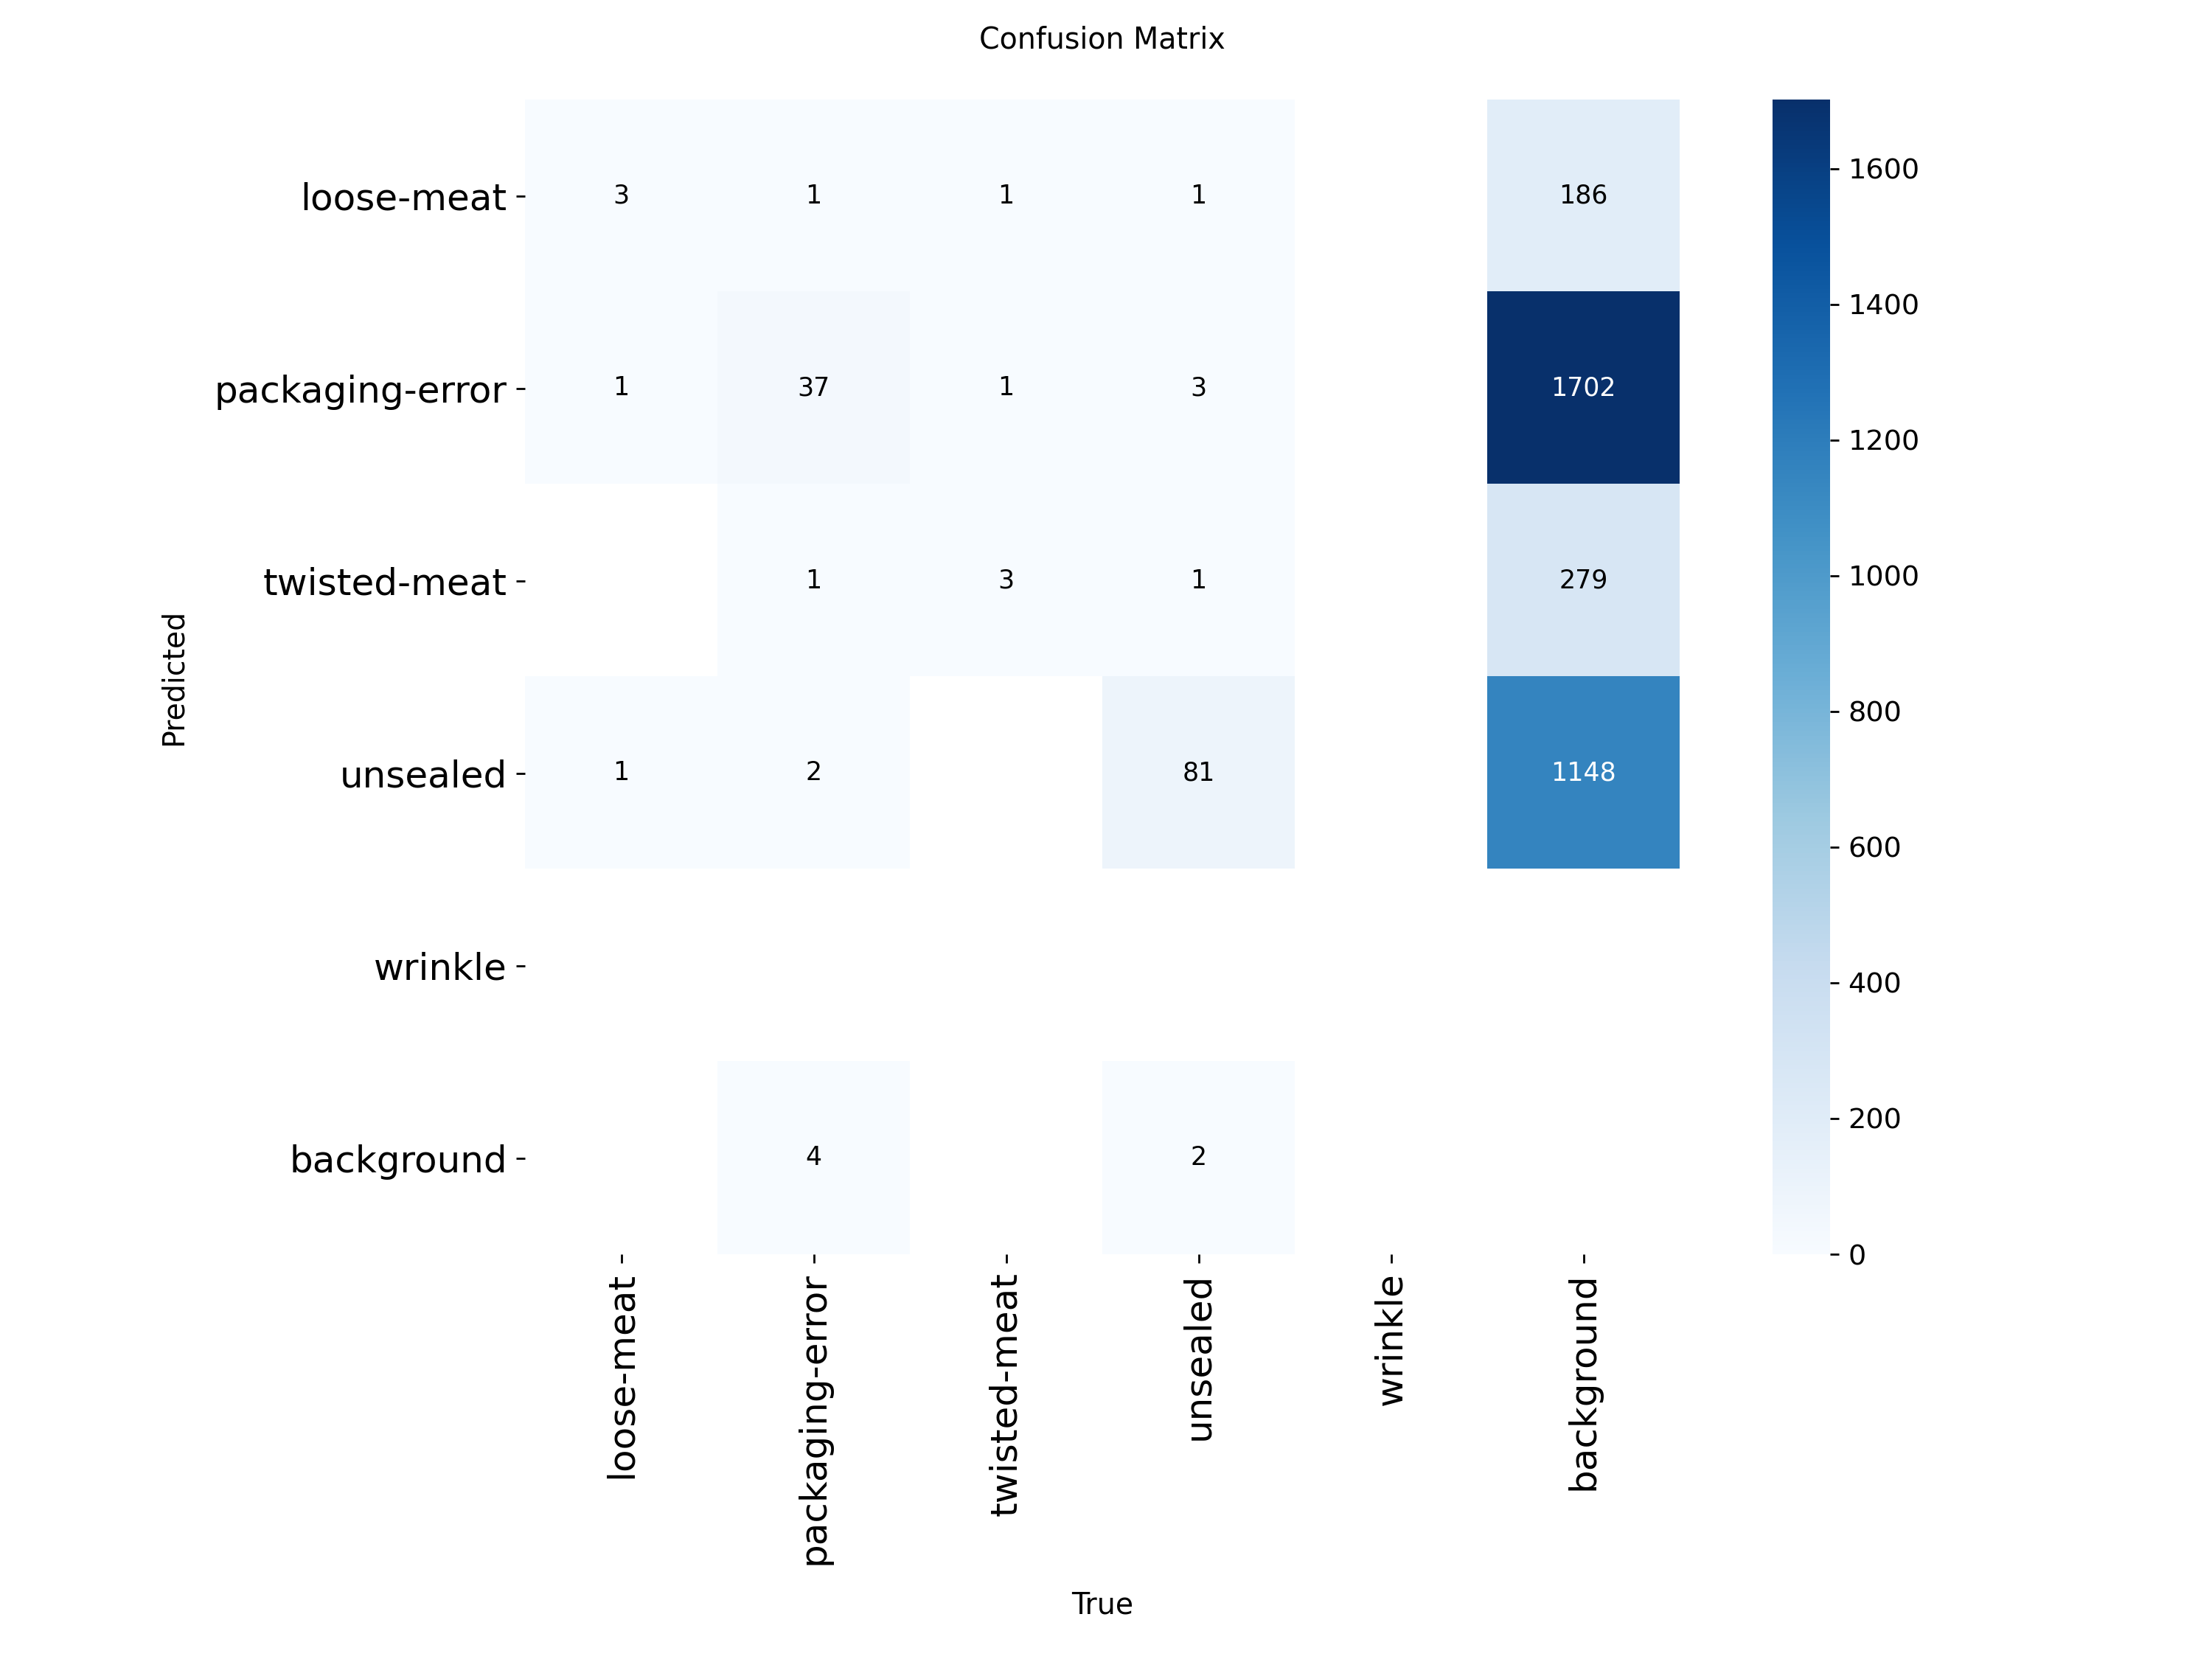

In [16]:
from IPython.display import Image, display

display(Image(
    filename="/content/mma3001_results/yolov8n_baseline/results.png"
))


display(Image(
    filename="/content/mma3001_results/yolov8n_baseline/confusion_matrix.png"
))

In [17]:
from ultralytics import YOLO

model = YOLO(
    "/content/mma3001_results/yolov8n_baseline/weights/best.pt"
)

print("Model loaded successfully")

results = model.predict(
    source="/content/Pork-Rasher-Error(Packaging)-1/test/images",
    conf=0.25,
    save=True,
    save_txt=True,
    save_conf=True
)

print("Prediction complete!")



Model loaded successfully

image 1/76 /content/Pork-Rasher-Error(Packaging)-1/test/images/frame_with_red_102_jpg.rf.8659eac39d6481b97dd7cd9cd5b53d10.jpg: 640x640 1 unsealed, 6.4ms
image 2/76 /content/Pork-Rasher-Error(Packaging)-1/test/images/frame_with_red_121_jpg.rf.b9703132d3c2ed0d47b4abbff0161da4.jpg: 640x640 1 twisted-meat, 7.0ms
image 3/76 /content/Pork-Rasher-Error(Packaging)-1/test/images/frame_with_red_1271_jpg.rf.22e9aa3a2caa406e08bbe0e9cc1979a7.jpg: 640x640 1 unsealed, 6.7ms
image 4/76 /content/Pork-Rasher-Error(Packaging)-1/test/images/frame_with_red_1298_jpg.rf.dd1b58a843b4aa0fa35a3deb2d94a00b.jpg: 640x640 (no detections), 10.0ms
image 5/76 /content/Pork-Rasher-Error(Packaging)-1/test/images/frame_with_red_1405_jpg.rf.dffa5de43a67cd0101bc0d29a4761afe.jpg: 640x640 1 unsealed, 9.4ms
image 6/76 /content/Pork-Rasher-Error(Packaging)-1/test/images/frame_with_red_1427_jpg.rf.bbc3b5eb81e27d8beaad124f9cd2cbff.jpg: 640x640 1 unsealed, 6.6ms
image 7/76 /content/Pork-Rasher-Error(Pac

In [18]:
import glob

prediction_dirs = glob.glob("/content/runs/detect/*")
print(prediction_dirs)

['/content/runs/detect/predict-2', '/content/runs/detect/val', '/content/runs/detect/predict']


Predicted images: 76
frame_with_red_6338_jpg.rf.e3e0d8bf789af3c67536ab2fe08b28dc.jpg


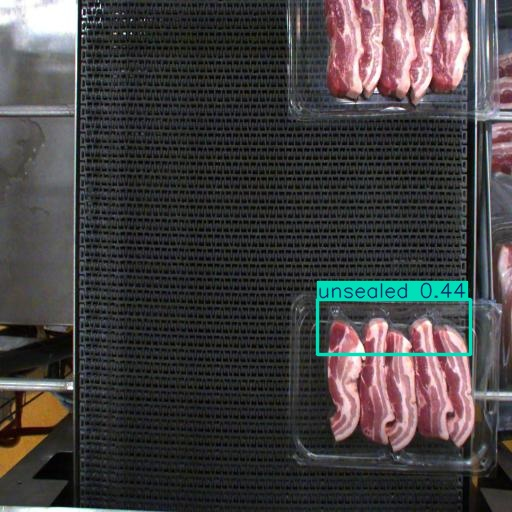

frame_with_red_889_jpg.rf.23eaf4d0dbad3b8e5e9ea9435771b13b.jpg


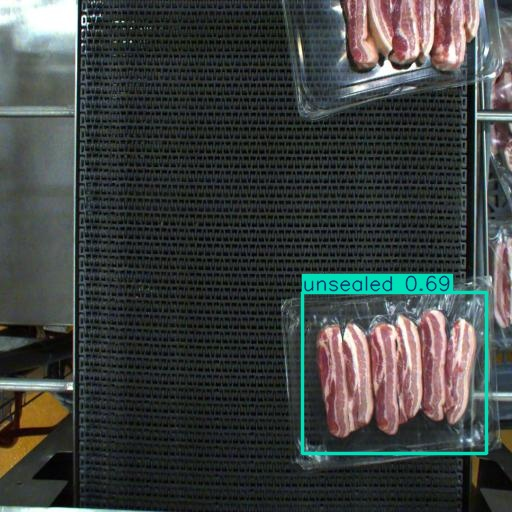

frame_with_red_3117_jpg.rf.cdf863ce7b666dc7e8d388dde3a79c6b.jpg


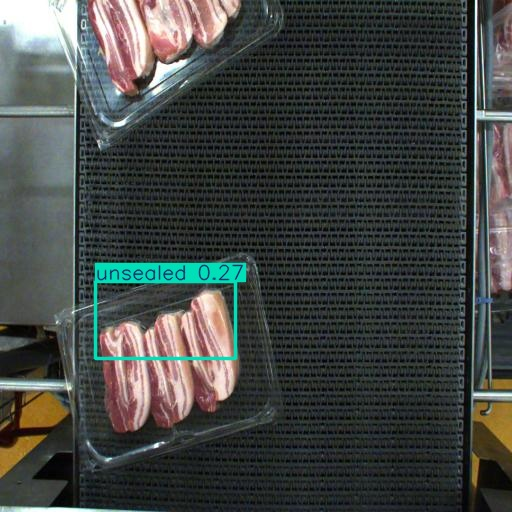

frame_with_red_4027_jpg.rf.5adf1a6a209ff1e040058164049270fe.jpg


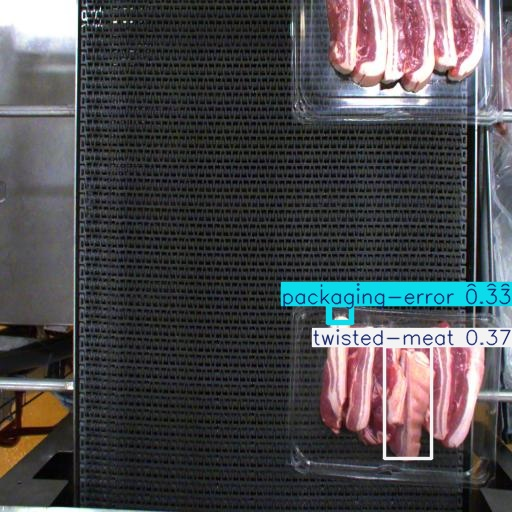

frame_with_red_21_jpg.rf.bcfbc816395a5f74f1c19190f6136a56.jpg


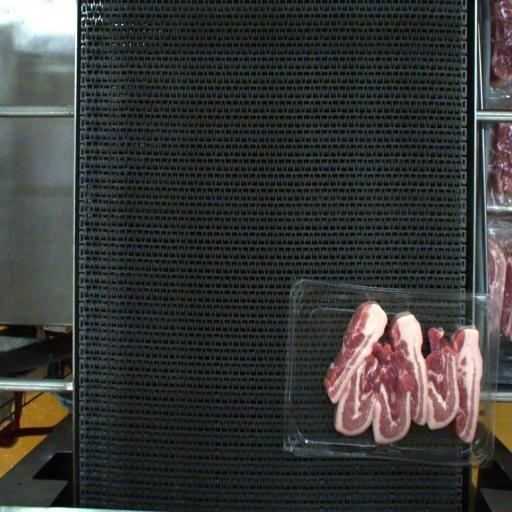

In [19]:
from pathlib import Path
from IPython.display import Image, display

prediction_dir = Path("/content/runs/detect/predict")

images = list(prediction_dir.glob("*.jpg")) + list(prediction_dir.glob("*.png"))

print("Predicted images:", len(images))

for img in images[:5]:
    print(img.name)
    display(Image(filename=str(img)))

Inspect my training data

In [20]:
from pathlib import Path
from collections import Counter

dataset_path = Path("/content/Pork-Rasher-Error(Packaging)-1")

label_files = list(
    (dataset_path / "train" / "labels").glob("*.txt")
)

class_counts = Counter()

for label_file in label_files:
    with open(label_file, "r") as f:
        for line in f:
            if line.strip():
                class_id = int(line.split()[0])
                class_counts[class_id] += 1

print("Training instances by class:")

for class_id, count in sorted(class_counts.items()):
    print(class_id, count)




import yaml

with open("/content/Pork-Rasher-Error(Packaging)-1/data.yaml", "r") as f:
    data = yaml.safe_load(f)

print(data["names"])

Training instances by class:
0 127
1 1372
2 236
3 479
4 18
['loose-meat', 'packaging-error', 'twisted-meat', 'unsealed', 'wrinkle']


In [21]:
from ultralytics import YOLO

model = YOLO(
    "/content/mma3001_results/yolov8n_baseline/weights/best.pt"
)

model.val(
    data="/content/Pork-Rasher-Error(Packaging)-1/data.yaml",
    split="test",
    plots=True,
    save_json=True
)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2152.4±647.7 MB/s, size: 50.2 KB)
val: Scanning /content/Pork-Rasher-Error(Packaging)-1/test/labels... 76 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 76/76 2.0Kit/s 0.0s
val: New cache created: /content/Pork-Rasher-Error(Packaging)-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.9it/s 2.6s
                   all         76         91      0.665      0.583      0.673      0.264
            loose-meat          2          3      0.828          1      0.995      0.267
       packaging-error         22         29      0.513     0.0345      0.356     0.0882
          twisted-meat          7          7      0.474      0.571      0.595      0.301
              unsealed         51         52 

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7c1179fcdf60>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0

In [22]:
from pathlib import Path
from collections import Counter
import yaml

dataset_path = Path(
    "/content/Pork-Rasher-Error(Packaging)-1"
)

# Load class names
with open(dataset_path / "data.yaml", "r") as f:
    data = yaml.safe_load(f)

print("Classes:")
for i, name in enumerate(data["names"]):
    print(f"{i}: {name}")

# Count training instances
label_dir = dataset_path / "train" / "labels"

class_counts = Counter()

for label_file in label_dir.glob("*.txt"):
    with open(label_file, "r") as f:
        for line in f:
            if line.strip():
                class_id = int(line.split()[0])
                class_counts[class_id] += 1

print("\nTraining instances:")
for class_id, count in sorted(class_counts.items()):
    name = data["names"][class_id]
    print(f"{name}: {count}")

Classes:
0: loose-meat
1: packaging-error
2: twisted-meat
3: unsealed
4: wrinkle

Training instances:
loose-meat: 127
packaging-error: 1372
twisted-meat: 236
unsealed: 479
wrinkle: 18


In [23]:
from pathlib import Path
import yaml
from ultralytics import YOLO

dataset_path = Path(
    "/content/Pork-Rasher-Error(Packaging)-1"
)

model_path = (
    "/content/mma3001_results/"
    "yolov8n_baseline/weights/best.pt"
)

# 1. Inspect dataset configuration
with open(dataset_path / "data.yaml", "r") as f:
    data = yaml.safe_load(f)

print("DATASET CONFIGURATION")
print("Names:", data.get("names"))
print("Number of classes:", data.get("nc"))
print("Train:", data.get("train"))
print("Validation:", data.get("val"))
print("Test:", data.get("test"))

# 2. Inspect trained model
model = YOLO(model_path)

print("\nTRAINED MODEL")
print("Model class names:", model.names)
print("Number of model classes:", len(model.names))

# 3. Inspect saved training arguments
args_path = (
    Path("/content/mma3001_results/")
    / "yolov8n_baseline" / "args.yaml"
)

if args_path.exists():
    with open(args_path, "r") as f:
        args = yaml.safe_load(f)

    print("\nTRAINING ARGUMENTS")
    for key in [
        "model", "data", "epochs", "imgsz",
        "batch", "patience", "augment",
        "close_mosaic", "fliplr", "flipud",
        "degrees", "scale", "mosaic"
    ]:
        print(f"{key}: {args.get(key)}")
else:
    print("\nargs.yaml not found; inspect the run folder.")

DATASET CONFIGURATION
Names: ['loose-meat', 'packaging-error', 'twisted-meat', 'unsealed', 'wrinkle']
Number of classes: 5
Train: ../train/images
Validation: ../valid/images
Test: ../test/images

TRAINED MODEL
Model class names: {0: 'loose-meat', 1: 'packaging-error', 2: 'twisted-meat', 3: 'unsealed', 4: 'wrinkle'}
Number of model classes: 5

TRAINING ARGUMENTS
model: yolov8n.pt
data: /content/Pork-Rasher-Error(Packaging)-1/data.yaml
epochs: 50
imgsz: 640
batch: 16
patience: 10
augment: False
close_mosaic: 10
fliplr: 0.5
flipud: 0.0
degrees: 0.0
scale: 0.5
mosaic: 1.0


In [26]:

from ultralytics import YOLO
import os

# Dataset path
DATA_YAML = "/content/Pork-Rasher-Error(Packaging)-1/data.yaml"

# Output directory
PROJECT_DIR = "/content/mma3001_results"
RUN_NAME = "yolov8n_corrected_augmented"

# Check that the dataset configuration exists
if not os.path.exists(DATA_YAML):
    raise FileNotFoundError(
        f"Dataset configuration not found: {DATA_YAML}\n"
        "Update DATA_YAML to your actual dataset path."
    )

# Start from the same pretrained YOLOv8n model
model_aug = YOLO("yolov8n.pt")

# Experiment 2: explicit data augmentation
results_aug = model_aug.train(
    data=DATA_YAML,

    # Training settings
    epochs=60,
    imgsz=640,
    batch=16,
    device=0,
    patience=15,

    # Save results
    project=PROJECT_DIR,
    name=RUN_NAME,
    exist_ok=True,

    # Explicit augmentation
    augment=True,
    hsv_h=0.015,
    hsv_s=0.5,
    hsv_v=0.3,
    degrees=5.0,
    translate=0.1,
    scale=0.5,
    fliplr=0.5,
    flipud=0.0,
    mosaic=1.0,
    close_mosaic=10,

    # Reproducibility and plots
    plots=True,
    seed=42
)

# Best model checkpoint
BEST_MODEL = os.path.join(
    PROJECT_DIR, RUN_NAME, "weights", "best.pt"
)

if os.path.exists(BEST_MODEL):
    print("\nTraining completed successfully.")
    print(f"Best model saved at: {BEST_MODEL}")
else:
    raise FileNotFoundError(
        f"Best model checkpoint not found: {BEST_MODEL}"
    )




from ultralytics import YOLO
import os

# Use the same dataset configuration as training
DATA_YAML = "/content/Pork-Rasher-Error(Packaging)-1/data.yaml"

BEST_MODEL = (
    "/content/mma3001_results/"
    "yolov8n_corrected_augmented/weights/best.pt"
)

# Check files exist
if not os.path.exists(DATA_YAML):
    raise FileNotFoundError(f"Dataset not found: {DATA_YAML}")

if not os.path.exists(BEST_MODEL):
    raise FileNotFoundError(f"Model not found: {BEST_MODEL}")

# Load the best checkpoint
aug_model = YOLO(BEST_MODEL)

# Validate using consistent evaluation settings
metrics_aug = aug_model.val(
    data=DATA_YAML,
    split="val",
    imgsz=640,
    batch=16,
    device=0,
    conf=0.001,
    iou=0.7,
    plots=True,
    project="/content/mma3001_results",
    name="yolov8n_corrected_augmented_val"
)

# Print overall metrics
print("\n" + "=" * 45)
print("CORRECTED AUGMENTED MODEL — VALIDATION RESULTS")
print("=" * 45)

print(f"Precision:  {metrics_aug.box.mp:.4f}")
print(f"Recall:     {metrics_aug.box.mr:.4f}")
print(f"mAP@50:     {metrics_aug.box.map50:.4f}")
print(f"mAP@50-95:  {metrics_aug.box.map:.4f}")

print("\nPer-class mAP@50:")
for class_id, class_name in aug_model.names.items():
    if class_id < len(metrics_aug.box.maps):
        print(
            f"{class_name}: "
            f"{metrics_aug.box.maps[class_id]:.4f}"
        )

print("\nValidation results and plots saved.")


Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=True, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Pork-Rasher-Error(Packaging)-1/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.3, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_corrected_augmented, nbs=64, nms=